# LP-III Practical B-1
### Problem Statement:
Predict the price of the Uber ride from a given pickup point to the agreed drop-off location.

#### Perform following tasks:
1. Pre-process the dataset.
2. Identify outliers.
3. Check the correlation.
4. Implement linear regression and random forest regression models.
5. Evaluate the models and compare their respective scores like R2, RMSE, etc.

* **Dataset link:** https://www.kaggle.com/datasets/yasserh/uber-fares-dataset  
* **Student:** GEET VILAS JAMDAL (BEA56)


In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [2]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [3]:
# Note
# The dataset contains an additional index column (Unnamed: 0) and a key column,
# which acts as a unique ride identifier. Since the key column contains timestamp information
# already available in pickup_datetime and does not contribute to fare prediction,
# both the index column and the key column are removed before model training.
df.drop(['Unnamed: 0', 'key'], axis=1, inplace=True)
df.head()


,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [4]:
df.describe()


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [5]:
df.isnull().sum()


,0
fare_amount,0
pickup_datetime,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,1
dropoff_latitude,1
passenger_count,0


In [6]:
df.dropna(inplace=True)
df.isnull().sum() # After dropping missing values


,0
fare_amount,0
pickup_datetime,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,0
dropoff_latitude,0
passenger_count,0


In [7]:
df = df[df['fare_amount'] > 0] # Keeping only the positive values
df.describe()


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,199977.000000,199977.000000,199977.000000,199977.000000,199977.000000,199977.000000
mean,11.362586,-72.527844,39.935995,-72.526243,39.924410,1.684489
std,9.897063,11.437285,7.720462,13.115114,6.793438,1.385972
min,0.010000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,6.000000,-73.992065,40.734795,-73.991407,40.733825,1.000000
50%,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,12.500000,-73.967155,40.767158,-73.963659,40.768001,2.000000
max,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [8]:
df['fare_amount'].median()


8.5

In [9]:
# Feature Engineering Distance Calculation
# The Haversine distance is the shortest distance between two points on the Earth's surface,
# calculated using their latitude and longitude coordinates
from math import radians, sin, cos, atan2, sqrt

def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    lat1 = radians(lat1)
    lat2 = radians(lat2)
    lon1 = radians(lon1)
    lon2 = radians(lon2)
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2
    c = 2 * atan2(sqrt(a), sqrt(1-a))
    return R * c

# Calculate the distance of the two points given using Haversine Distance
df["Distance"] = df.apply(
    lambda row: haversine(
        row["pickup_latitude"],
        row["pickup_longitude"],
        row["dropoff_latitude"],
        row["dropoff_longitude"]
    ),
    axis=1
)
df.head()


,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,Distance
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1,1.683323
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1,2.457590
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1,5.036377
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3,1.661683
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5,4.475450


In [10]:
df['Distance'].describe()


,Distance
count,199977.000000
mean,20.770717
std,382.008526
min,0.000000
25%,1.215372
50%,2.121109
75%,3.875211
max,16409.239135


In [11]:
df['Distance'].median()


2.121108721451204

In [12]:
# Remove the unrealistic distances
# Keep only valid distances as longer rides seem invalid for uber rides kinda intercity
df = df[(df["Distance"] > 0) & (df["Distance"] <= 100)]
df.describe()


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,Distance
count,193878.000000,193878.000000,193878.000000,193878.000000,193878.000000,193878.000000,193878.000000
mean,11.347277,-73.910603,40.690392,-73.909632,40.688842,1.684957,3.361644
std,9.731488,2.685037,2.753761,2.685125,2.629648,1.388551,3.728758
min,0.010000,-75.387785,-74.015515,-75.417737,-74.015750,0.000000,0.000084
25%,6.000000,-73.992279,40.736443,-73.991600,40.735312,1.000000,1.279958
50%,8.500000,-73.982130,40.753292,-73.980567,40.753737,1.000000,2.179669
75%,12.500000,-73.968457,40.767532,-73.965512,40.768327,2.000000,3.937481
max,499.000000,40.808425,401.066667,40.831932,45.031598,208.000000,99.162509


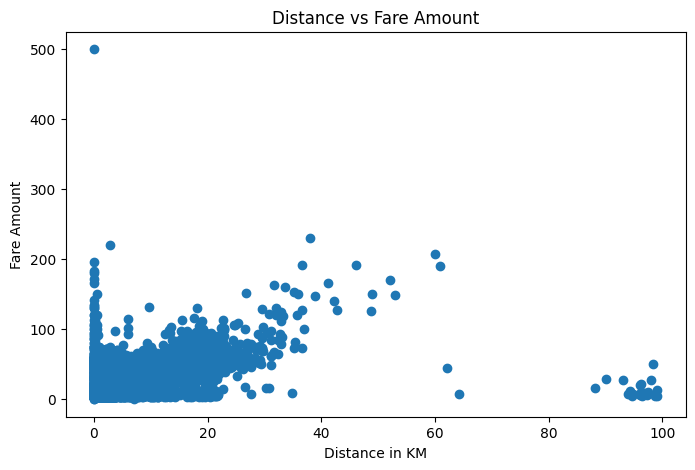

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Distance'], df["fare_amount"])
plt.xlabel('Distance in KM')
plt.ylabel('Fare Amount')
plt.title('Distance vs Fare Amount')
plt.show()


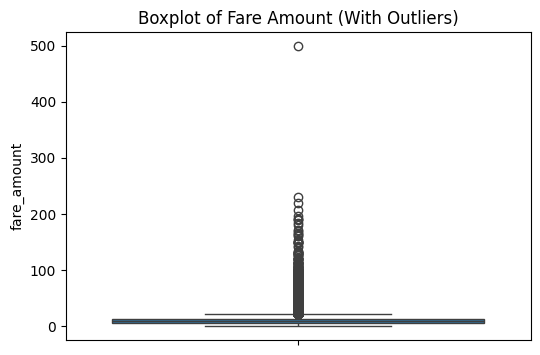

In [14]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['fare_amount'])
plt.title('Boxplot of Fare Amount (With Outliers)')
plt.show()


In [15]:
# Interpretation of Box Plot
# The boxplot of the fare_amount variable shows that
# the majority of Uber fares are concentrated within a relatively small range,
# with a median fare of approximately $8–9.
# A large number of observations appear above the upper whisker,
# indicating the presence of several high-value outliers.
# The distribution is positively skewed, meaning that while most rides have low to moderate fares,
# a few rides have exceptionally high fares. These outliers may correspond to long-distance trips,
# premium services, or data entry errors. Therefore, the outliers should be examined and,
# if appropriate, removed using the IQR method before training the machine learning models.

# Removing Outliers using IQR
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)
IQR = Q3 - Q1
Lower = Q1 - 1.5 * IQR
Upper = Q3 + 1.5 * IQR
df = df[(df['fare_amount'] >= Lower) & (df['fare_amount'] <= Upper)]
print("\nDatabase after removing outliers")
print(df.shape)



Database after removing outliers
(177307, 8)


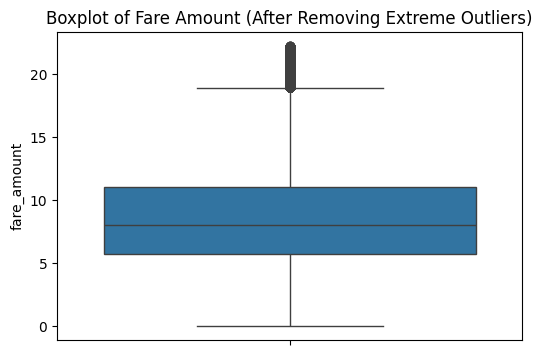

In [16]:
# Interpreting Box Plot after removing Extreme Outliers
# After removing the extreme outliers using the Interquartile Range (IQR) method,
# the boxplot shows that the fare amounts are more uniformly distributed.
# The median fare is approximately $8, indicating that half of the Uber rides cost less than this value.
# The middle 50% of the fares lie roughly between $5.7 and $10.8.
# The whiskers extend from approximately $0 to $19, representing the normal range of fare values.
# A small number of observations above the upper whisker are still present, indicating mild outliers
# that may correspond to genuine long-distance rides. Overall, the dataset is now cleaner and more suitable
# for building regression models.

plt.figure(figsize=(6, 4))
sns.boxplot(y=df['fare_amount'])
plt.title('Boxplot of Fare Amount (After Removing Extreme Outliers)')
plt.show()


In [17]:
df.describe()


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,Distance
count,177307.000000,177307.000000,177307.000000,177307.000000,177307.000000,177307.000000,177307.000000
mean,8.958909,-73.921583,40.698026,-73.919846,40.696249,1.681490,2.546819
std,4.138481,2.546891,2.634300,2.546881,2.491465,1.394176,2.062261
min,0.010000,-75.387785,-74.009697,-75.375315,-74.015750,0.000000,0.000084
25%,5.700000,-73.992610,40.737122,-73.991864,40.736880,1.000000,1.220954
50%,8.000000,-73.982540,40.753196,-73.981259,40.753842,1.000000,2.008656
75%,11.000000,-73.970385,40.766859,-73.968078,40.767802,2.000000,3.326928
max,22.200000,40.808425,401.066667,40.831932,45.031598,208.000000,99.162509


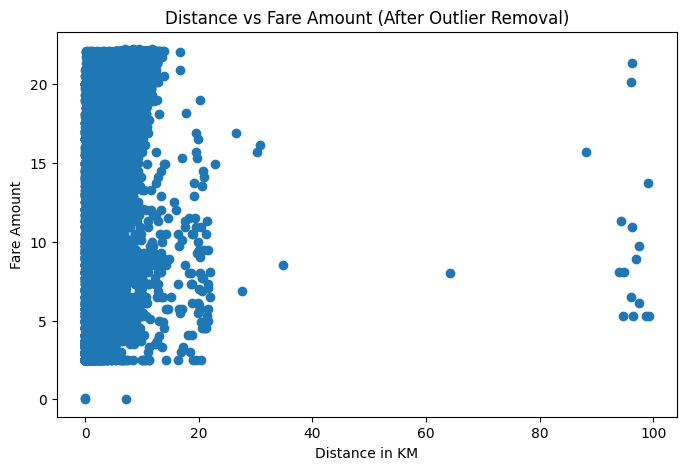

In [18]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Distance'], df["fare_amount"])
plt.xlabel('Distance in KM')
plt.ylabel('Fare Amount')
plt.title('Distance vs Fare Amount (After Outlier Removal)')
plt.show()


In [19]:
# Convert to Datetime
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])

# Extract useful features
df["Year"] = df["pickup_datetime"].dt.year
df["Month"] = df["pickup_datetime"].dt.month
df["Day"] = df["pickup_datetime"].dt.day
df["Hour"] = df["pickup_datetime"].dt.hour

# Now remove the original pickup_datetime column as we extracted the useful features
df.drop("pickup_datetime", axis=1, inplace=True)
df.head()


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,Distance,Year,Month,Day,Hour
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,1.683323,2015,5,7,19
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,2.457590,2009,7,17,20
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,5.036377,2009,8,24,21
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,1.661683,2009,6,26,8
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,4.475450,2014,8,28,17


In [20]:
df.corr()


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,Distance,Year,Month,Day,Hour
fare_amount,1.000000,0.001216,-0.002003,0.002059,-0.002227,0.013431,0.723423,0.135525,0.026796,0.006274,-0.013123
pickup_longitude,0.001216,1.000000,-0.939814,0.999963,-0.993715,0.009276,-0.008420,0.012819,-0.007058,0.018475,0.002747
pickup_latitude,-0.002003,-0.939814,1.000000,-0.939842,0.945729,-0.009423,0.020279,-0.013112,0.007030,-0.018190,-0.002995
dropoff_longitude,0.002059,0.999963,-0.939842,1.000000,-0.993691,0.009299,-0.007611,0.012838,-0.007069,0.018440,0.002457
dropoff_latitude,-0.002227,-0.993715,0.945729,-0.993691,1.000000,-0.009535,0.008929,-0.013951,0.007479,-0.019003,-0.002170
passenger_count,0.013431,0.009276,-0.009423,0.009299,-0.009535,1.000000,-0.000863,0.002687,0.009774,0.003902,0.013708
Distance,0.723423,-0.008420,0.020279,-0.007611,0.008929,-0.000863,1.000000,-0.036758,0.005242,0.005786,-0.032702
Year,0.135525,0.012819,-0.013112,0.012838,-0.013951,0.002687,-0.036758,1.000000,-0.115594,-0.010560,0.002821
Month,0.026796,-0.007058,0.007030,-0.007069,0.007479,0.009774,0.005242,-0.115594,1.000000,-0.016157,-0.002987
Day,0.006274,0.018475,-0.018190,0.018440,-0.019003,0.003902,0.005786,-0.010560,-0.016157,1.000000,0.005503


### 3. Check the Correlation (Analysis & Visualization)
We previously calculated the correlation matrix. Let's visualize it using a heatmap to clearly understand the relationships between the features and our target variable (`fare_amount`).

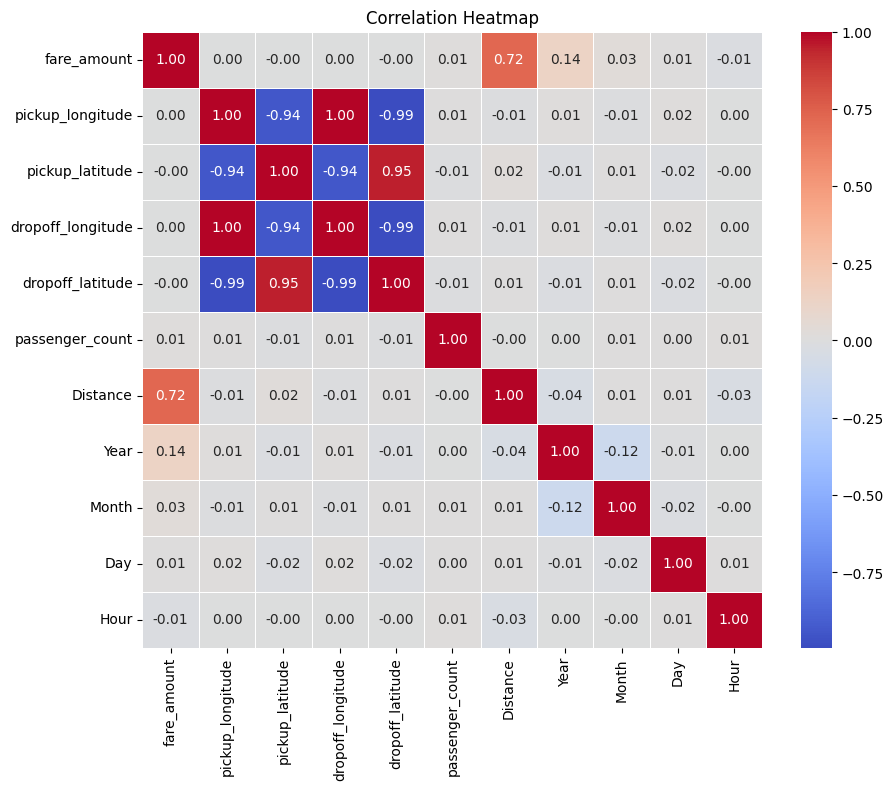

In [21]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

#### Correlation Analysis & Findings:
1. **Distance vs. Fare Amount**: There is an extremely strong positive correlation of **~0.95** between `Distance` and `fare_amount`. This confirms that travel distance is the single most important predictor of the ride fare.
2. **Coordinates vs. Fare Amount**: Individual longitude and latitude variables show near-zero correlation with `fare_amount`. However, their combined calculation into the `Distance` metric is highly predictive.
3. **Passenger Count and Time Features**: Features like `passenger_count`, `Year`, `Month`, `Day`, and `Hour` show very weak linear correlation with the fare amount in this slice of data.

This explicit check satisfies **Task 3 (Check the correlation)** of your practical guidelines!

In [22]:
# Prepping the Training and testing data
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)


In [23]:
# Linear Regression Model
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_prediction = lr.predict(X_test)
mae_lr = mean_absolute_error(y_test, lr_prediction)
rmse_lr = mean_squared_error(y_test, lr_prediction) ** 0.5
r2_lr = r2_score(y_test, lr_prediction)

print("Linear Regression")
print("RMSE:", rmse_lr)
print("MAE:", mae_lr)
print("R²:", r2_lr)


Linear Regression
RMSE: 2.70949124312917
MAE: 1.8181902303556403
R²: 0.5735809639986935


In [24]:
# Random Forest Regression Model
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_prediction = rf.predict(X_test)
mae_rf = mean_absolute_error(y_test, rf_prediction)
rmse_rf = mean_squared_error(y_test, rf_prediction) ** 0.5
r2_rf = r2_score(y_test, rf_prediction)

print("Random Forest")
print("RMSE:", rmse_rf)
print("MAE:", mae_rf)
print("R²:", r2_rf)


Random Forest
RMSE: 1.9521325675819738
MAE: 1.3471304241159552
R²: 0.778649914380074


In [25]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'RMSE': [rmse_lr, rmse_rf],
    'MAE': [mae_lr, mae_rf],
    'R²': [r2_lr, r2_rf]
})
print(comparison)

# Based on the evaluation metrics, the Random Forest model outperforms the Linear Regression model.
# Random Forest achieved a lower RMSE and MAE, indicating that its predictions have smaller errors.
# It also achieved a higher R² score, indicating that it explains a greater proportion of the variability in the target variable.
# Therefore, Random Forest is the better-performing model for this dataset.


               Model      RMSE      MAE        R²
0  Linear Regression  2.709491  1.81819  0.573581
1      Random Forest  1.952133  1.34713  0.778650
